[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/20_pytorch_essentials.ipynb)

# 20 · PyTorch Essentials: The Same Ideas, at Scale

**Part 3 — Deep learning** · Notebook 20 of 27

In notebook 19 we wrote a neural network by hand: forward pass, backward pass, gradient check, SGD loop. That's the best way to understand it, and the worst way to build anything big. Every new layer type would need its own hand-derived backward pass, and NumPy can't use a GPU.

**PyTorch** keeps the same ideas and automates the tedious parts. Its tensors are NumPy arrays that can live on a GPU; its **autograd** records every operation and computes all gradients for you (exactly the computation-graph engine we built in notebook 04, industrial-strength); and its `nn` and `optim` modules package layers, losses, and optimizers. This notebook learns PyTorch by rebuilding things we already understand, then trains real networks on **Fashion-MNIST**, 70,000 photos of clothing, and develops the habits that make deep learning work in practice: a standard training loop, sanity checks, regularization, and debugging.

**What you'll learn**

1. Tensors: NumPy with superpowers
2. Autograd: gradients for free (checked against notebook 04)
3. Linear regression four ways, from manual gradients to `nn` + `optim`
4. `nn.Module`: building networks out of parts
5. Data: Fashion-MNIST, `Dataset` and `DataLoader`
6. The training loop, and a first real model
7. Optimizers and learning-rate schedules, compared
8. Regularization in practice: dropout, weight decay, batch normalization
9. Debugging a network: the checklist that saves hours
10. GPUs, saving models, and reproducibility
11. Looking at what the model gets wrong

*Course map: this notebook supports CX 4240 lectures 11–13 and ISYE 4600 W10 (neural networks trained by backpropagation and SGD) by moving from hand-written NumPy to the tools used in practice; the autograd section revisits notebook 04 (CX 4240 lecture 11's worked backprop example).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
import torch, torch.nn as nn, torch.nn.functional as F
import time, gzip, os, urllib.request
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__}, running on: {device}")
print("Ready ✓")

Setup complete ✓


PyTorch 2.14.1+cu130, running on: cpu
Ready ✓


> 💡 **Using a GPU on Colab:** `Runtime → Change runtime type → T4 GPU`, then re-run. Everything here also runs on the CPU (the default), just more slowly; the notebook trains on a 20,000-image subset by default so it finishes in a few minutes either way.

---
## 1. Tensors: NumPy with superpowers

A `torch.Tensor` is an n-dimensional array, like `np.ndarray`, with nearly the same operations: creation, indexing, broadcasting, matrix multiplication, reductions. Two additions matter: tensors can live on a **GPU**, and they can **track the operations** applied to them so that gradients can be computed.

In [2]:
a = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
print("a =", a, "\nshape:", a.shape, " dtype:", a.dtype, " device:", a.device)
print("\nzeros / ones / random:", torch.zeros(2, 2).shape, torch.ones(3).shape, torch.randn(2, 3).shape)
print("arange and reshape:\n", torch.arange(12).reshape(3, 4))
b = torch.tensor([10.0, 20.0, 30.0])
print("\nbroadcasting a + b (b is added to every row):\n", a + b)
print("matrix product a @ aᵀ:\n", a @ a.T)
print("reductions: sum", a.sum().item(), " mean of each column", a.mean(dim=0))

# NumPy interop: .numpy() and torch.from_numpy share memory on the CPU
arr = np.arange(4.0); t = torch.from_numpy(arr); arr[0] = 99
print("\nshared memory: changing the NumPy array changed the tensor:", t)

a = tensor([[1., 2., 3.],
        [4., 5., 6.]]) 
shape: torch.Size([2, 3])  dtype: torch.float32  device: cpu

zeros / ones / random: torch.Size([2, 2]) torch.Size([3]) torch.Size([2, 3])
arange and reshape:
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])

broadcasting a + b (b is added to every row):
 tensor([[11., 22., 33.],
        [14., 25., 36.]])
matrix product a @ aᵀ:
 tensor([[14., 32.],
        [32., 77.]])
reductions: sum 21.0  mean of each column tensor([2.5000, 3.5000, 4.5000])

shared memory: changing the NumPy array changed the tensor: tensor([99.,  1.,  2.,  3.], dtype=torch.float64)


A few habits that prevent bugs:

- **Shapes first.** Most PyTorch errors are shape mismatches. Print `.shape` liberally. By convention the first dimension is the **batch**: a batch of 128 grayscale 28×28 images is a tensor of shape `(128, 1, 28, 28)`.
- **dtype.** Neural networks use `float32` (NumPy defaults to `float64`). Class labels for losses are `int64` (`torch.long`).
- **device.** Every tensor in an operation must be on the same device; `.to(device)` moves it.
- `.item()` turns a one-element tensor into a Python number.

---
## 2. Autograd: gradients for free

Set `requires_grad=True` on a tensor and PyTorch records every operation that uses it into a **computation graph**. Calling `.backward()` on a scalar result runs reverse-mode differentiation through that graph and stores $\partial(\text{result})/\partial(\text{tensor})$ in each leaf's `.grad`. That's notebook 04's `Value` engine, for tensors.

Let's check it against notebook 04's worked example from CX 4240 lecture 11: a tiny network $\ell = (o(Vh) - y)^2$, $h = \sigma(Wx)$, where we derived the gradients by hand.

In [3]:
torch.manual_seed(1)
x = torch.tensor([0.5, -1.0]); y = torch.tensor(1.0)
W = torch.randn(3, 2, requires_grad=True); V = torch.randn(3, requires_grad=True)

h = torch.sigmoid(W @ x)                 # hidden layer
o = torch.sigmoid(V @ h)                 # output
loss = (o - y) ** 2
loss.backward()                          # one call: all gradients

# The hand-derived gradients (notebook 04):  δ = 2(o − y)·o(1 − o)
with torch.no_grad():
    delta = 2 * (o - y) * o * (1 - o)
    dV = delta * h
    dW = torch.outer(delta * V * h * (1 - h), x)
print("∂ℓ/∂V  autograd:", V.grad.numpy().round(6), "\n       by hand: ", dV.numpy().round(6))
print("∂ℓ/∂W  autograd:\n", W.grad.numpy().round(6), "\n       by hand:\n", dW.numpy().round(6))

∂ℓ/∂V  autograd: [-0.143228 -0.098975 -0.134654] 
       by hand:  [-0.143228 -0.098975 -0.134654]
∂ℓ/∂W  autograd:
 [[ 0.052788 -0.105576]
 [-0.012154  0.024309]
 [ 0.035627 -0.071255]] 
       by hand:
 [[ 0.052788 -0.105576]
 [-0.012154  0.024309]
 [ 0.035627 -0.071255]]


Identical. Three autograd behaviors trip everyone up at least once:

In [4]:
w = torch.tensor(3.0, requires_grad=True)
for i in range(3):
    (w ** 2).backward()
    print(f"after backward #{i + 1}: w.grad = {w.grad.item()}   (true gradient of w² at 3 is 6)")
w.grad.zero_()
print("after w.grad.zero_():", w.grad.item())

with torch.no_grad():                    # no graph is recorded: use for evaluation and for parameter updates
    z = w * 2
print("inside no_grad, z.requires_grad =", z.requires_grad)
print("w.detach() shares data but is cut out of the graph:", w.detach().requires_grad)

after backward #1: w.grad = 6.0   (true gradient of w² at 3 is 6)
after backward #2: w.grad = 12.0   (true gradient of w² at 3 is 6)
after backward #3: w.grad = 18.0   (true gradient of w² at 3 is 6)
after w.grad.zero_(): 0.0
inside no_grad, z.requires_grad = False
w.detach() shares data but is cut out of the graph: False


1. **Gradients accumulate.** Each `.backward()` *adds* to `.grad` (useful for summing gradients over several mini-batches, surprising otherwise). That's why every training loop calls `optimizer.zero_grad()` before `backward()`.
2. **`torch.no_grad()`** turns recording off: use it for evaluation (faster, less memory) and when updating parameters by hand (an update shouldn't itself be differentiated).
3. **`.detach()`** returns a tensor cut out of the graph, e.g. to plot a value or use it as a fixed target.

---
## 3. Linear regression four ways

The fastest way to learn the PyTorch idiom is to write the same model with less and less manual work. Data: $y = 3x - 2 + \text{noise}$.

In [5]:
torch.manual_seed(0)
Xl = torch.rand(200, 1) * 4 - 2; yl = 3 * Xl - 2 + 0.5 * torch.randn(200, 1)
results = {}

# (1) NumPy-style: manual gradients
w_, b_ = torch.zeros(1), torch.zeros(1)
for step in range(300):
    err = (Xl * w_ + b_) - yl
    w_ -= 0.1 * 2 * (err * Xl).mean(); b_ -= 0.1 * 2 * err.mean()
results["1. manual gradients"] = (w_.item(), b_.item())

# (2) autograd computes the gradients; we still update by hand
w_ = torch.zeros(1, requires_grad=True); b_ = torch.zeros(1, requires_grad=True)
for step in range(300):
    loss = ((Xl * w_ + b_ - yl) ** 2).mean()
    loss.backward()
    with torch.no_grad():
        w_ -= 0.1 * w_.grad; b_ -= 0.1 * b_.grad
        w_.grad.zero_(); b_.grad.zero_()
results["2. autograd + manual update"] = (w_.item(), b_.item())

# (3) an optimizer does the update and the zeroing
w_ = torch.zeros(1, requires_grad=True); b_ = torch.zeros(1, requires_grad=True)
opt = torch.optim.SGD([w_, b_], lr=0.1)
for step in range(300):
    loss = ((Xl * w_ + b_ - yl) ** 2).mean()
    opt.zero_grad(); loss.backward(); opt.step()
results["3. autograd + torch.optim"] = (w_.item(), b_.item())

# (4) the idiomatic version: a layer, a loss function, an optimizer
model = nn.Linear(1, 1); loss_fn = nn.MSELoss(); opt = torch.optim.SGD(model.parameters(), lr=0.1)
for step in range(300):
    loss = loss_fn(model(Xl), yl)
    opt.zero_grad(); loss.backward(); opt.step()
results["4. nn.Linear + nn.MSELoss + optim"] = (model.weight.item(), model.bias.item())

# closed form (notebook 05) for reference
A = torch.cat([Xl, torch.ones_like(Xl)], 1); sol = torch.linalg.lstsq(A, yl).solution.squeeze()
results["normal equation (exact)"] = (sol[0].item(), sol[1].item())
pd.DataFrame(results, index=["slope w", "intercept b"]).T.round(4)

,slope w,intercept b
1. manual gradients,3.0237,-2.0397
2. autograd + manual update,3.0237,-2.0397
3. autograd + torch.optim,3.0237,-2.0397
4. nn.Linear + nn.MSELoss + optim,3.0237,-2.0397
normal equation (exact),3.0237,-2.0397


All four reach the least-squares answer. Version 4's three-line loop body is the pattern every PyTorch training loop follows, from this toy to large language models:

```python
loss = loss_fn(model(inputs), targets)   # forward
optimizer.zero_grad()                    # clear old gradients
loss.backward()                          # backward: autograd fills .grad
optimizer.step()                         # update the parameters
```

---
## 4. `nn.Module`: building networks out of parts

A model is a subclass of `nn.Module`: create the layers in `__init__`, describe the computation in `forward`. Any layer assigned as an attribute is registered automatically, so `model.parameters()` finds all its weights. Here's notebook 19's MLP:

In [6]:
class MLP(nn.Module):
    def __init__(self, sizes, dropout=0.0, batchnorm=False):
        super().__init__()
        layers = []
        for n_in, n_out in zip(sizes[:-2], sizes[1:-1]):
            layers.append(nn.Linear(n_in, n_out))
            if batchnorm: layers.append(nn.BatchNorm1d(n_out))
            layers.append(nn.ReLU())
            if dropout > 0: layers.append(nn.Dropout(dropout))
        layers.append(nn.Linear(sizes[-2], sizes[-1]))       # last layer: raw scores ("logits"), no softmax
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x.flatten(1))                        # (batch, 1, 28, 28) → (batch, 784)

model = MLP([784, 256, 128, 10])
print(model)
n_params = sum(p.numel() for p in model.parameters())
print(f"\n{n_params:,} parameters:", [tuple(p.shape) for p in model.parameters()])

MLP(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

235,146 parameters: [(256, 784), (256,), (128, 256), (128,), (10, 128), (10,)]


`nn.Sequential` chains layers in order. Notice the last layer outputs raw scores (**logits**), not probabilities: `nn.CrossEntropyLoss` (or `F.cross_entropy`) applies log-softmax internally, which is more numerically stable than computing softmax and then its log (notebook 08's log-sum-exp trick). Apply `softmax` yourself only when you want to *read* probabilities.

---
## 5. Data: Fashion-MNIST

**Fashion-MNIST** (Xiao, Rasul & Vollgraf, 2017; Zalando) has 70,000 grayscale 28 × 28 photos of clothing in 10 classes, as a harder drop-in replacement for handwritten digits. We download the four files straight from the dataset's official GitHub repository (about 30 MB) and parse them with NumPy.

train: (60000, 1, 28, 28) test: (10000, 1, 28, 28)   pixel range: 0 – 255


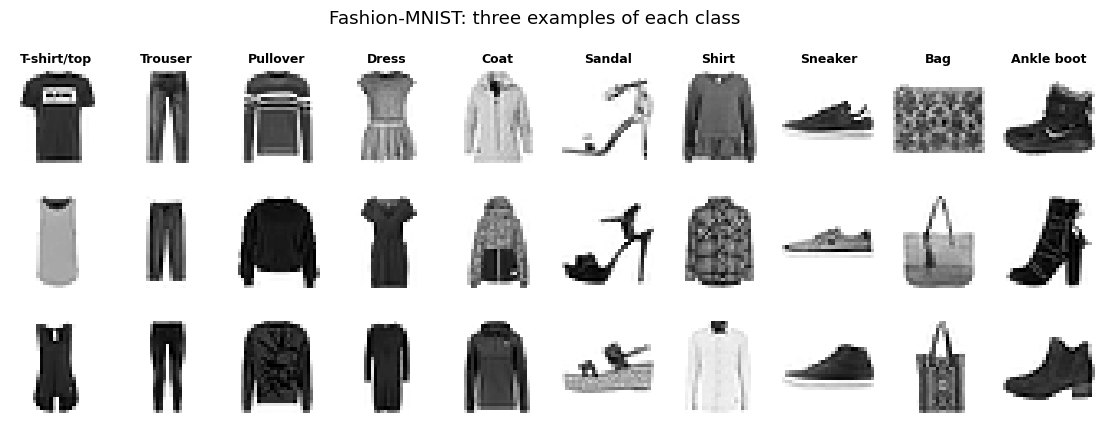

In [7]:
FMNIST_URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

def load_fashion_mnist(root="data/fashion"):
    os.makedirs(root, exist_ok=True); out = {}
    for split, prefix in [("train", "train"), ("test", "t10k")]:
        for kind, offset in [("images", 16), ("labels", 8)]:
            fname = f"{prefix}-{kind}-idx{3 if kind == 'images' else 1}-ubyte.gz"; path = os.path.join(root, fname)
            if not os.path.exists(path): urllib.request.urlretrieve(FMNIST_URL + fname, path)
            out[(split, kind)] = np.frombuffer(gzip.open(path).read(), np.uint8, offset=offset)
    Xtr = out[("train", "images")].reshape(-1, 1, 28, 28); Xte = out[("test", "images")].reshape(-1, 1, 28, 28)
    return Xtr, out[("train", "labels")], Xte, out[("test", "labels")]

Xtr_all, ytr_all, Xte_np, yte_np = load_fashion_mnist()
print("train:", Xtr_all.shape, "test:", Xte_np.shape, "  pixel range:", Xtr_all.min(), "–", Xtr_all.max())
fig, axes = plt.subplots(3, 10, figsize=(14, 4.6))
for c in range(10):
    for r in range(3):
        img = Xtr_all[np.flatnonzero(ytr_all == c)[r], 0]
        axes[r, c].imshow(img, cmap="gray_r"); axes[r, c].axis("off")
    axes[0, c].set_title(CLASSES[c], fontsize=9)
fig.suptitle("Fashion-MNIST: three examples of each class", y=1.0); plt.show()

Shirts, T-shirts, pullovers, and coats look alike at 28 × 28, which is what makes this dataset harder than digits.

### `Dataset` and `DataLoader`

PyTorch separates **what** the data is (`Dataset`: a length and a way to get item `i`) from **how** it's served (`DataLoader`: shuffling, batching, parallel loading). For data that fits in memory, `TensorDataset` wraps tensors directly. We normalize pixels to mean 0 and standard deviation 1 using statistics from the **training** set only (notebook 06's leakage rule), and hold out 5,000 training images for validation.

In [8]:
N_TRAIN = 20000                                  # set to 55000 on a GPU runtime for the full training set
rng_np = np.random.default_rng(0); perm = rng_np.permutation(len(Xtr_all))
val_idx, tr_idx = perm[:5000], perm[5000:5000 + N_TRAIN]
mean, std = Xtr_all[tr_idx].mean() / 255, Xtr_all[tr_idx].std() / 255
to_tensor = lambda X: (torch.tensor(X, dtype=torch.float32) / 255 - mean) / std

from torch.utils.data import TensorDataset, DataLoader
train_ds = TensorDataset(to_tensor(Xtr_all[tr_idx]), torch.tensor(ytr_all[tr_idx], dtype=torch.long))
val_ds = TensorDataset(to_tensor(Xtr_all[val_idx]), torch.tensor(ytr_all[val_idx], dtype=torch.long))
test_ds = TensorDataset(to_tensor(Xte_np), torch.tensor(yte_np, dtype=torch.long))
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)        # reshuffled every epoch
val_dl = DataLoader(val_ds, batch_size=1000); test_dl = DataLoader(test_ds, batch_size=1000)

xb, yb = next(iter(train_dl))
print(f"{len(train_ds):,} training / {len(val_ds):,} validation / {len(test_ds):,} test images")
print("one batch:", xb.shape, xb.dtype, yb.shape, yb.dtype, f"  (pixel mean {xb.mean():.2f}, std {xb.std():.2f})")

20,000 training / 5,000 validation / 10,000 test images
one batch: torch.Size([128, 1, 28, 28]) torch.float32 torch.Size([128]) torch.int64   (pixel mean 0.06, std 1.01)


---
## 6. The training loop

Here is the loop, written once and reused for the rest of the notebook (and, in spirit, in every deep learning project). Two details beyond the four-line core:

- `model.train()` / `model.eval()` switch layers that behave differently during training (dropout, batch norm; section 8).
- Evaluation runs under `torch.no_grad()`.

In [9]:
def evaluate(model, dl):
    model.eval(); total, correct, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss_sum += F.cross_entropy(logits, yb, reduction="sum").item()
            correct += (logits.argmax(1) == yb).sum().item(); total += len(yb)
    return loss_sum / total, correct / total

def fit(model, epochs=8, lr=1e-3, opt="adam", weight_decay=0.0, schedule=None, train_dl=train_dl, verbose=True, seed=0):
    torch.manual_seed(seed); model.to(device)
    optim = {"sgd": lambda: torch.optim.SGD(model.parameters(), lr=lr, weight_decay=weight_decay),
             "momentum": lambda: torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay),
             "adam": lambda: torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay),
             "adamw": lambda: torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)}[opt]()
    sched = torch.optim.lr_scheduler.OneCycleLR(optim, max_lr=lr, total_steps=epochs * len(train_dl)) if schedule == "onecycle" else None
    hist = []
    for ep in range(epochs):
        model.train(); t0 = time.time(); run_loss, n = 0.0, 0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb)              # forward
            optim.zero_grad(); loss.backward(); optim.step()  # backward + update
            if sched: sched.step()
            run_loss += loss.item() * len(yb); n += len(yb)
        val_loss, val_acc = evaluate(model, val_dl)
        hist.append(dict(epoch=ep + 1, train_loss=run_loss / n, val_loss=val_loss, val_acc=val_acc))
        if verbose: print(f"epoch {ep + 1:2d}  train loss {run_loss / n:.3f}  val loss {val_loss:.3f}  val acc {val_acc:.1%}  ({time.time() - t0:.1f}s)")
    return pd.DataFrame(hist)

torch.manual_seed(0)
mlp = MLP([784, 256, 128, 10])
print(f"before training: val loss {evaluate(mlp.to(device), val_dl)[0]:.3f}  (log 10 = {np.log(10):.3f}: a fair guess among 10 classes)")
h_mlp = fit(mlp, epochs=8)

before training: val loss 2.325  (log 10 = 2.303: a fair guess among 10 classes)


epoch  1  train loss 0.616  val loss 0.472  val acc 82.2%  (0.4s)


epoch  2  train loss 0.409  val loss 0.431  val acc 84.0%  (0.4s)


epoch  3  train loss 0.362  val loss 0.387  val acc 85.4%  (0.4s)


epoch  4  train loss 0.330  val loss 0.377  val acc 85.1%  (0.4s)


epoch  5  train loss 0.300  val loss 0.410  val acc 84.9%  (0.4s)


epoch  6  train loss 0.286  val loss 0.374  val acc 86.5%  (0.4s)


epoch  7  train loss 0.264  val loss 0.373  val acc 86.2%  (0.4s)


epoch  8  train loss 0.248  val loss 0.362  val acc 86.5%  (0.4s)


The loss before training is close to $\log 10 \approx 2.30$, exactly what cross-entropy gives when the model spreads probability evenly over 10 classes: a quick sanity check that the setup is right (section 9). After a few epochs the MLP gets around 87% of validation images right. Compare simple baselines:

In [10]:
from sklearn.linear_model import LogisticRegression
import warnings; warnings.filterwarnings("ignore", message="lbfgs failed to converge")
Xflat = train_ds.tensors[0].flatten(1).numpy(); Xvflat = val_ds.tensors[0].flatten(1).numpy()
t0 = time.time(); logreg = LogisticRegression(max_iter=300).fit(Xflat[:10000], train_ds.tensors[1].numpy()[:10000])
print(f"logistic regression (10k images):  val acc {logreg.score(Xvflat, val_ds.tensors[1].numpy()):.1%}  ({time.time() - t0:.0f}s)")
print(f"MLP 784-256-128-10:                val acc {h_mlp.val_acc.iloc[-1]:.1%}")

logistic regression (10k images):  val acc 81.2%  (13s)
MLP 784-256-128-10:                val acc 86.5%


---
> 🚧 **This notebook is being written section by section.** The sections above are complete and run top to bottom; more are on the way.